# HCES 2023–24 — Household Consumption Segmentation

**Purpose:** rebuild a correctly keyed household-level table from the raw HCES files, calculate visit-adjusted monthly expenditure, cluster households, and export cluster assignments and profiles.

**Important:** This notebook deliberately does not use the earlier `hces_household_eda_sample.csv`, because that file was built with a shortened household ID that merged distinct survey records. It rebuilds the data using the identifiers in the raw files.

Run cells from top to bottom. Keep the four source CSVs in the `HCES_2023_24` folder beside this notebook, or change `DATA_DIR` in the next cell. Outputs are written to `outputs/`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt

RANDOM_STATE = 42
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "HCES_2023_24"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

L1_PATH = DATA_DIR / "LEVEL - 01(Section 1 and 1_1).csv"
L3_PATH = DATA_DIR / "LEVEL - 03.csv"
L5_PATH = DATA_DIR / "LEVEL - 05 ( Sec 5  6).csv"
L15_PATH = DATA_DIR / "LEVEL - 15 (Section 1_1, A2,B2  C2).csv"

for path in [L1_PATH, L3_PATH, L5_PATH, L15_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing file: {path}\nPut the four raw CSVs in {DATA_DIR} or update DATA_DIR."
        )

print("Data folder:", DATA_DIR.resolve())
print("Output folder:", OUTPUT_DIR.resolve())

Data folder: C:\Users\anuja\Downloads\HCES_Project\HCES_2023_24
Output folder: C:\Users\anuja\Downloads\HCES_Project\outputs


## 1. Load household-level source files and define a survey key

The key uses FSU, sample SU, second-stage stratum, and sample household number. `Sample_Sub_Division_No` is mostly blank in the supplied data, so it is not used to define the key. We validate uniqueness in Level 01 before proceeding.

In [2]:
KEY_COMPONENTS = [
    "FSU_Serial_No",
    "Sample_SU_No",
    "Second_Stage_Stratum_No",
    "Sample_Household_No",
]

def read_csv_clean(path, **kwargs):
    frame = pd.read_csv(path, encoding="utf-8-sig", low_memory=False, **kwargs)
    frame.columns = frame.columns.astype(str).str.strip()
    return frame

l1 = read_csv_clean(L1_PATH)
l3 = read_csv_clean(L3_PATH)

for name, frame in [("Level 01", l1), ("Level 03", l3)]:
    missing = [c for c in KEY_COMPONENTS if c not in frame.columns]
    if missing:
        raise KeyError(f"{name} is missing key fields: {missing}")

def make_hh_id(frame):
    # Normalize integer-like numeric identifiers consistently across files.
    parts = frame[KEY_COMPONENTS].copy()
    for col in KEY_COMPONENTS:
        parts[col] = (
            pd.to_numeric(parts[col], errors="coerce")
            .map(lambda x: "" if pd.isna(x) else str(int(x)) if float(x).is_integer() else str(x))
        )
    return parts.agg("_".join, axis=1)

l1["HH_ID"] = make_hh_id(l1)
l3["HH_ID"] = make_hh_id(l3)

print("Level 01 rows:", len(l1))
print("Level 01 unique HH_IDs:", l1["HH_ID"].nunique())
print("Level 01 duplicate HH_ID rows:", int(l1["HH_ID"].duplicated().sum()))
print("Level 03 rows:", len(l3))
print("Level 03 unique HH_IDs:", l3["HH_ID"].nunique())
print("Level 03 duplicate HH_ID rows:", int(l3["HH_ID"].duplicated().sum()))

if l1["HH_ID"].duplicated().any():
    raise ValueError("Level 01 is not unique on the proposed key. Stop and inspect the key before modeling.")
if l3["HH_ID"].duplicated().any():
    print("Level 03 has multiple rows per household; it will be deduplicated only after checking values.")

Level 01 rows: 261953
Level 01 unique HH_IDs: 261953
Level 01 duplicate HH_ID rows: 0
Level 03 rows: 261953
Level 03 unique HH_IDs: 261953
Level 03 duplicate HH_ID rows: 0


## 2. Merge household characteristics

The merge keeps one record per verified Level 01 household. For Level 03, exact duplicate household keys are collapsed to one row; if there are multiple rows per key, the first non-null value is retained per column and a warning is printed.

In [3]:
def collapse_one_row_per_household(frame, name):
    if not frame["HH_ID"].duplicated().any():
        return frame
    print(f"Warning: {name} has repeated HH_IDs; collapsing non-null values by first available value.")
    value_cols = [c for c in frame.columns if c != "HH_ID"]
    agg = {c: "first" for c in value_cols}
    return frame.groupby("HH_ID", as_index=False).agg(agg)

l1_hh = collapse_one_row_per_household(l1, "Level 01")
l3_hh = collapse_one_row_per_household(l3, "Level 03")

# Avoid duplicate key components and overlapping columns during merge.
l3_drop = [c for c in KEY_COMPONENTS if c in l3_hh.columns]
l3_for_merge = l3_hh.drop(columns=l3_drop, errors="ignore")
overlap = (set(l1_hh.columns) & set(l3_for_merge.columns)) - {"HH_ID"}
if overlap:
    l3_for_merge = l3_for_merge.rename(columns={c: f"{c}_L3" for c in overlap})

hh = l1_hh.merge(l3_for_merge, on="HH_ID", how="left", validate="one_to_one")
print("Merged household table:", hh.shape)
print("Unique households:", hh["HH_ID"].nunique())

size_candidates = [c for c in hh.columns if "HOUSEHOLD_SIZE" in c.upper() or c.upper() in {"HH_SIZE", "HH_SIZE_"}]
print("Potential household-size columns:", size_candidates)

Merged household table: (261953, 58)
Unique households: 261953
Potential household-size columns: []


## 3. Rebuild Level 15 expenditure using visits

Level 15 contains questionnaire records spread across visits. We first aggregate the A2/B2/C2 expenditure components **within each household and visit**, then apply the official visit adjustment:

`TE = E1 + (E2 / P2) * P1 + (E3 / P3) * P1`

where `E1`, `E2`, `E3` are the total expenditure amounts for Visits 1, 2, and 3, and `P1`, `P2`, `P3` are household sizes at those visits. The household size from Visit 1 is the reference.

The `H`/`SECTION 11` rows are excluded from expenditure totals because they do not contain the A2/B2/C2 expenditure components.

In [4]:
l15 = read_csv_clean(L15_PATH, dtype={"Questionnaire_No": "string"})
required_l15 = KEY_COMPONENTS + [
    "Questionnaire_No", "SECTION", "MONTHLY_CONSUMPTION_EXP",
    "ONLINE_EXPENDITURE", "HOUSEHOLD_SIZE"
]
missing = [c for c in required_l15 if c not in l15.columns]
if missing:
    raise KeyError(f"Level 15 missing required columns: {missing}")

l15["HH_ID"] = make_hh_id(l15)
l15["Questionnaire_No"] = l15["Questionnaire_No"].astype("string").str.strip()
for c in ["MONTHLY_CONSUMPTION_EXP", "ONLINE_EXPENDITURE", "HOUSEHOLD_SIZE"]:
    l15[c] = pd.to_numeric(l15[c], errors="coerce")

# H is the visit-3 household record and has no expenditure component.
# F, C, and D are the expenditure questionnaires; aggregate by questionnaire,
# not by VISIT, because VISIT numbers rotate across questionnaires.
exp_rows = l15[
    l15["Questionnaire_No"].isin(["F", "C", "D"])
    & l15["SECTION"].astype(str).str.strip().isin(["A2", "B2", "C2"])
].copy()

questionnaire_exp = (
    exp_rows.groupby(["HH_ID", "Questionnaire_No"], as_index=False)
    .agg(
        EXP=("MONTHLY_CONSUMPTION_EXP", "sum"),
        ONLINE_EXP=("ONLINE_EXPENDITURE", "sum"),
        HH_SIZE=("HOUSEHOLD_SIZE", "first"),
        ROWS=("SECTION", "size"),
    )
)

# One expenditure component and household size per questionnaire.
# If duplicate rows remain within a full household key and questionnaire,
# stop rather than silently summing potentially duplicated survey records.
dup_counts = questionnaire_exp.groupby("HH_ID")["Questionnaire_No"].nunique()
if questionnaire_exp.duplicated(["HH_ID", "Questionnaire_No"]).any():
    raise ValueError("Duplicate household-questionnaire aggregates detected.")
if not questionnaire_exp["Questionnaire_No"].isin(["F", "C", "D"]).all():
    raise ValueError("Unexpected questionnaire code in expenditure rows.")

def pivot_component(value_col, prefix):
    wide = questionnaire_exp.pivot(index="HH_ID", columns="Questionnaire_No", values=value_col)
    wide = wide.rename(columns={"F": f"{prefix}_F", "C": f"{prefix}_C", "D": f"{prefix}_D"})
    return wide

exp_wide = pivot_component("EXP", "E")
online_wide = pivot_component("ONLINE_EXP", "ONLINE")
size_wide = pivot_component("HH_SIZE", "P")
exp_household = exp_wide.join(online_wide, how="outer").join(size_wide, how="outer").reset_index()

for col in ["E_F", "E_C", "E_D", "ONLINE_F", "ONLINE_C", "ONLINE_D", "P_F", "P_C", "P_D"]:
    if col not in exp_household.columns:
        exp_household[col] = np.nan

# Official HCES adjustment: FDQ (F) is the reference household size.
# TE = E_F + (E_C / P_C) * P_F + (E_D / P_D) * P_F.
P1 = exp_household["P_F"]
valid_all = (
    exp_household["E_F"].notna()
    & exp_household["E_C"].notna()
    & exp_household["E_D"].notna()
    & P1.gt(0)
    & exp_household["P_C"].gt(0)
    & exp_household["P_D"].gt(0)
)
exp_household["MONTHLY_EXP"] = np.nan
exp_household.loc[valid_all, "MONTHLY_EXP"] = (
    exp_household.loc[valid_all, "E_F"]
    + (exp_household.loc[valid_all, "E_C"] / exp_household.loc[valid_all, "P_C"]) * P1[valid_all]
    + (exp_household.loc[valid_all, "E_D"] / exp_household.loc[valid_all, "P_D"]) * P1[valid_all]
)
exp_household["ONLINE_EXP"] = np.nan
exp_household.loc[valid_all, "ONLINE_EXP"] = (
    exp_household.loc[valid_all, "ONLINE_F"]
    + (exp_household.loc[valid_all, "ONLINE_C"] / exp_household.loc[valid_all, "P_C"]) * P1[valid_all]
    + (exp_household.loc[valid_all, "ONLINE_D"] / exp_household.loc[valid_all, "P_D"]) * P1[valid_all]
)
exp_household["HH_SIZE"] = P1
exp_household["PER_CAPITA_EXP"] = exp_household["MONTHLY_EXP"] / P1.where(P1.gt(0))
exp_household["ONLINE_FLAG"] = (exp_household["ONLINE_EXP"].fillna(0) > 0).astype("int8")
exp_household["ONLINE_SHARE"] = exp_household["ONLINE_EXP"] / exp_household["MONTHLY_EXP"].where(exp_household["MONTHLY_EXP"].gt(0))

print("Expenditure questionnaire rows (F/C/D):", len(exp_rows))
print("Unique expenditure household IDs:", exp_household["HH_ID"].nunique())
print("Households with all three expenditure components:", int(valid_all.sum()))
print("Missing components by questionnaire:")
display(exp_household[["E_F", "E_C", "E_D", "P_F", "P_C", "P_D"]].isna().sum().to_frame("Missing"))


Expenditure questionnaire rows (F/C/D): 785859
Unique expenditure household IDs: 261953
Households with all three expenditure components: 261953
Missing components by questionnaire:


,Missing
Questionnaire_No,
E_F,0
E_C,0
E_D,0
P_F,0
P_C,0
P_D,0


## 4. Join expenditure to household characteristics and run validation checks

Households without all three visits are retained in the household table, but expenditure-derived clustering features are used only when the adjusted measure is calculable. This notebook reports coverage and flags extreme values rather than silently replacing missing visit data.

In [5]:
hh = hh.drop(columns=[
    "MONTHLY_EXP", "ONLINE_EXP", "PER_CAPITA_EXP", "ONLINE_FLAG", "ONLINE_SHARE",
    "HH_SIZE", "P_F", "P_C", "P_D", "E_F", "E_C", "E_D"
], errors="ignore")
hh = hh.merge(
    exp_household[[
        "HH_ID", "MONTHLY_EXP", "ONLINE_EXP", "PER_CAPITA_EXP",
        "ONLINE_FLAG", "ONLINE_SHARE", "HH_SIZE",
        "P_F", "P_C", "P_D", "E_F", "E_C", "E_D"
    ]],
    on="HH_ID",
    how="left",
    validate="one_to_one"
)

print("Final household rows:", len(hh))
print("Unique HH_IDs:", hh["HH_ID"].nunique())
print("Duplicate HH_IDs:", int(hh["HH_ID"].duplicated().sum()))
print("Share with calculable adjusted expenditure:", round(hh["MONTHLY_EXP"].notna().mean() * 100, 2), "%")

display(
    hh[[
        "MONTHLY_EXP", "PER_CAPITA_EXP", "ONLINE_EXP", "ONLINE_SHARE", "HH_SIZE"
    ]].describe().T
)


Final household rows: 261953
Unique HH_IDs: 261953
Duplicate HH_IDs: 0
Share with calculable adjusted expenditure: 100.0 %


,count,mean,std,min,25%,50%,75%,max
MONTHLY_EXP,261953.0,38716.664627,22821.725282,600.0,24000.0,34000.0,48000.000000,462000.000000
PER_CAPITA_EXP,261953.0,10873.961389,8098.018425,600.0,6000.0,8750.0,13000.000000,243000.000000
ONLINE_EXP,261953.0,1795.198391,4247.302086,0.0,0.0,0.0,1800.000000,135000.000000
ONLINE_SHARE,261953.0,0.036847,0.069479,0.0,0.0,0.0,0.044444,0.947368
HH_SIZE,261953.0,4.218539,2.072702,1.0,3.0,4.0,5.000000,31.000000


## 5. Select household segmentation features

We use household characteristics and validated expenditure features. Monetary features are log-transformed to reduce skew. We exclude raw identifier fields, survey weights, visit-specific intermediate values, and any columns that would leak identifiers into clusters.

In [6]:
categorical_candidates = [
    "Sector", "State", "Household_Type", "Religion_of_HH_Head",
    "Social_Group_of_HH_Head", "Max_Income_Activity",
    "Self_Employment_Source_Sector", "Regular_Wage_Source_Sector",
    "Casual_Labour_Source_Sector", "Land_Ownership",
    "Energy_Source_Cooking", "Energy_Source_Lighting", "Ration_Card_Type"
]
categorical_cols = [c for c in categorical_candidates if c in hh.columns]

# Identify household size. Prefer the official visit-1 household size.
if "HH_SIZE" not in hh.columns:
    hh["HH_SIZE"] = pd.to_numeric(hh.get("P_VISIT_1"), errors="coerce")

numeric_base = ["HH_SIZE", "Total_Area_Land_Owned_Acres"]
numeric_cols = [c for c in numeric_base if c in hh.columns]
for c in numeric_cols:
    hh[c] = pd.to_numeric(hh[c], errors="coerce")

# Keep expenditure features only for records where all three visits are available.
hh["LOG_PER_CAPITA_EXP"] = np.log1p(pd.to_numeric(hh["PER_CAPITA_EXP"], errors="coerce").clip(lower=0))
hh["LOG_MONTHLY_EXP"] = np.log1p(pd.to_numeric(hh["MONTHLY_EXP"], errors="coerce").clip(lower=0))
hh["LOG_ONLINE_EXP"] = np.log1p(pd.to_numeric(hh["ONLINE_EXP"], errors="coerce").clip(lower=0))
hh["ONLINE_SHARE_CAPPED"] = pd.to_numeric(hh["ONLINE_SHARE"], errors="coerce").clip(lower=0, upper=1)

spending_features = [
    "LOG_PER_CAPITA_EXP", "LOG_MONTHLY_EXP", "LOG_ONLINE_EXP",
    "ONLINE_SHARE_CAPPED", "ONLINE_FLAG"
]
numeric_cols = list(dict.fromkeys(numeric_cols + spending_features))
numeric_cols = [c for c in numeric_cols if c in hh.columns]

print("Categorical features:", categorical_cols)
print("Numeric features:", numeric_cols)

Categorical features: ['Sector', 'State', 'Household_Type', 'Religion_of_HH_Head', 'Social_Group_of_HH_Head', 'Max_Income_Activity', 'Self_Employment_Source_Sector', 'Regular_Wage_Source_Sector', 'Casual_Labour_Source_Sector', 'Land_Ownership', 'Energy_Source_Cooking', 'Energy_Source_Lighting', 'Ration_Card_Type']
Numeric features: ['HH_SIZE', 'Total_Area_Land_Owned_Acres', 'LOG_PER_CAPITA_EXP', 'LOG_MONTHLY_EXP', 'LOG_ONLINE_EXP', 'ONLINE_SHARE_CAPPED', 'ONLINE_FLAG']


## 6. Prepare the modeling population and encode features

For the primary clustering, rows need a valid per-capita expenditure and visit-1 household size. This keeps cluster interpretations tied to the validated consumption measure. Missing categorical values become `Unknown`; missing numeric predictors are median-imputed.

In [7]:
model_cols = categorical_cols + numeric_cols
model = hh[["HH_ID"] + model_cols].copy()

# Use households with calculated per-capita expenditure and a positive household size.
valid_mask = (
    model["LOG_PER_CAPITA_EXP"].notna()
    & pd.to_numeric(model["HH_SIZE"], errors="coerce").gt(0)
)
model = model.loc[valid_mask].copy()

for c in categorical_cols:
    model[c] = model[c].astype("string").fillna("Unknown")

for c in numeric_cols:
    model[c] = pd.to_numeric(model[c], errors="coerce")
    med = model[c].median()
    model[c] = model[c].fillna(med if pd.notna(med) else 0)

if len(model) < 100:
    raise ValueError(
        f"Only {len(model)} households have usable expenditure data. "
        "Check visit coverage before clustering."
    )

print("Households used for clustering:", len(model))
print("Feature matrix missing values:", int(model[model_cols].isna().sum().sum()))

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), categorical_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

X_processed = preprocessor.fit_transform(model[model_cols])
print("Encoded feature matrix:", X_processed.shape)

Households used for clustering: 261953
Feature matrix missing values: 0
Encoded feature matrix: (261953, 107)


## 7. Choose a cluster count using a reproducible sample

We test K = 3 to 7 using MiniBatchKMeans. Silhouette is calculated on a fixed random sample to keep runtime manageable. The selected K is the best silhouette among the tested values; interpretability should still be reviewed before using segments for business decisions.

In [8]:
rng = np.random.default_rng(RANDOM_STATE)
sample_n = min(10000, X_processed.shape[0])
sample_idx = rng.choice(X_processed.shape[0], size=sample_n, replace=False)
X_sample = X_processed[sample_idx]

k_results = []
for k in range(3, 8):
    km = MiniBatchKMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        batch_size=4096,
        n_init=3,
        max_iter=100
    )
    labels_sample = km.fit_predict(X_sample)
    sil = silhouette_score(X_sample, labels_sample, sample_size=min(5000, sample_n), random_state=RANDOM_STATE)
    k_results.append({"k": k, "silhouette": sil, "inertia": km.inertia_})
    print(f"K={k}: silhouette={sil:.4f}, inertia={km.inertia_:.2f}")

k_results = pd.DataFrame(k_results)
display(k_results)

best_k = int(k_results.loc[k_results["silhouette"].idxmax(), "k"])
print("Selected K:", best_k)

K=3: silhouette=0.1105, inertia=100809.79
K=4: silhouette=0.1025, inertia=93814.48
K=5: silhouette=0.1101, inertia=89781.71
K=6: silhouette=0.1181, inertia=88798.81
K=7: silhouette=0.0867, inertia=84731.61


,k,silhouette,inertia
0,3,0.110502,100809.786463
1,4,0.102534,93814.477792
2,5,0.110103,89781.713366
3,6,0.118134,88798.813321
4,7,0.086697,84731.606929


Selected K: 6


## 8. Fit final clusters and profile them

The model is fitted to the full eligible household population. Profiles report household counts, median expenditure, online spending rate, household size, and key categorical distributions.

In [9]:
kmeans = MiniBatchKMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    batch_size=4096,
    n_init=5,
    max_iter=150
)
model["Cluster"] = kmeans.fit_predict(X_processed)

cluster_sizes = (
    model["Cluster"].value_counts().sort_index()
    .rename_axis("Cluster").to_frame("Households")
)
cluster_sizes["Share_Percent"] = cluster_sizes["Households"] / len(model) * 100
display(cluster_sizes.round(2))

# Keep HH_ID as an ordinary column throughout cluster profiling.
cluster_map = model.set_index("HH_ID")["Cluster"]
profile_source = hh.loc[hh["HH_ID"].isin(cluster_map.index)].copy()
profile_source["Cluster"] = profile_source["HH_ID"].map(cluster_map)

if profile_source["Cluster"].isna().any():
    raise ValueError("Some households could not be matched to a cluster label.")

profile_numeric = [
    c for c in ["HH_SIZE", "MONTHLY_EXP", "PER_CAPITA_EXP", "ONLINE_EXP", "ONLINE_SHARE"]
    if c in profile_source.columns
]
cluster_profile = profile_source.groupby("Cluster").agg(
    Households=("HH_ID", "nunique"),
    **{f"Median_{c}": (c, "median") for c in profile_numeric},
    **({"Online_Spending_Rate": ("ONLINE_FLAG", "mean")} if "ONLINE_FLAG" in profile_source.columns else {})
).reset_index()

if "Online_Spending_Rate" in cluster_profile.columns:
    cluster_profile["Online_Spending_Rate"] *= 100

display(cluster_profile.round(2))

for c in ["Sector", "State", "Household_Type", "Social_Group_of_HH_Head"]:
    if c in profile_source.columns:
        print(f"\nCluster composition by {c} (% within cluster)")
        composition = pd.crosstab(profile_source["Cluster"], profile_source[c], normalize="index") * 100
        display(composition.round(1))

,Households,Share_Percent
Cluster,,
0,57618,22.00
1,20862,7.96
2,38815,14.82
3,47535,18.15
4,54946,20.98
5,42177,16.10


,Cluster,Households,Median_HH_SIZE,Median_MONTHLY_EXP,Median_PER_CAPITA_EXP,Median_ONLINE_EXP,Median_ONLINE_SHARE,Online_Spending_Rate
0,0,57618,4.0,32700.0,7857.14,1100.0,0.04,100.00
1,1,20862,6.0,43600.0,7480.56,1000.0,0.02,81.72
2,2,38815,5.0,26500.0,6000.00,0.0,0.00,0.58
3,3,47535,4.0,22800.0,6020.00,0.0,0.00,0.24
4,4,54946,4.0,56000.0,16250.00,3800.0,0.07,100.00
5,5,42177,3.0,36000.0,12000.00,0.0,0.00,0.02



Cluster composition by Sector (% within cluster)


Sector,1,2
Cluster,,
0,60.4,39.6
1,92.9,7.1
2,94.0,6.0
3,90.3,9.7
4,11.7,88.3
5,33.9,66.1



Cluster composition by State (% within cluster)


State,1,2,3,4,5,6,7,8,9,10,...,28,29,30,31,32,33,34,35,36,37
Cluster,,,,,,,,,,,,,,,,,,,,,
0,1.7,1.2,2.3,0.1,1.3,1.3,1.5,3.6,11.8,6.8,...,5.2,5.7,0.2,0.4,3.5,6.4,0.2,0.2,2.5,0.3
1,0.6,0.9,2.2,0.0,0.7,2.5,0.1,12.3,11.3,3.4,...,3.0,7.7,0.0,0.1,0.8,1.5,0.0,0.1,3.7,0.2
2,1.0,0.3,1.8,0.0,0.6,1.3,0.0,4.9,15.9,13.9,...,2.6,3.1,0.1,0.1,1.0,4.6,0.2,0.2,0.8,0.1
3,0.5,0.5,0.6,0.0,1.1,0.7,0.1,5.8,19.2,10.3,...,3.0,3.2,0.1,0.0,0.5,3.1,0.1,0.1,1.1,0.2
4,1.4,1.5,2.9,0.9,1.3,3.5,4.0,3.5,5.0,1.3,...,3.2,5.8,0.8,0.3,5.2,6.1,1.0,0.9,4.1,0.2
5,2.5,0.8,3.9,0.3,0.9,2.9,0.5,4.5,7.4,3.8,...,6.2,4.1,0.3,0.3,4.1,9.2,0.7,0.6,3.4,0.6



Cluster composition by Household_Type (% within cluster)


Household_Type,1,2,3,4,5,6,9
Cluster,,,,,,,
0,26.2,26.1,8.2,14.4,7.6,11.6,6.0
1,86.2,8.1,0.2,3.8,0.3,0.7,0.6
2,0.8,1.5,5.5,4.7,37.3,49.2,1.0
3,59.7,18.6,1.8,4.7,0.4,0.0,14.6
4,27.7,50.2,3.0,6.3,0.2,0.4,12.1
5,23.1,28.9,13.2,11.1,2.3,1.4,19.9



Cluster composition by Social_Group_of_HH_Head (% within cluster)


Social_Group_of_HH_Head,0,1,2,3,9
Cluster,,,,,
0,0.2,11.8,18.4,46.0,23.5
1,0.1,21.5,8.2,43.9,26.3
2,0.3,18.3,31.4,36.6,13.4
3,0.1,19.7,16.6,44.1,19.3
4,0.8,9.9,9.3,33.9,46.1
5,0.6,8.6,16.7,41.6,32.5


## 9. Visualize the clusters in two dimensions

Truncated SVD projects the sparse encoded feature matrix to two dimensions for visualization. This is a visual aid, not a measure of cluster quality.

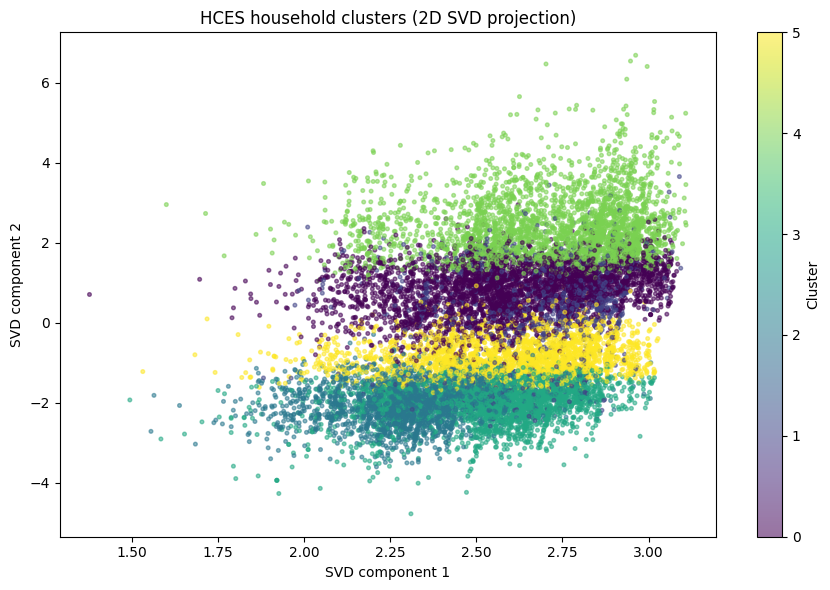

Explained variance ratio (two SVD components): 0.2462


In [10]:
svd = TruncatedSVD(n_components=2, random_state=RANDOM_STATE)
coords = svd.fit_transform(X_processed)

plot_n = min(15000, len(model))
plot_idx = np.random.default_rng(RANDOM_STATE).choice(len(model), size=plot_n, replace=False)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    coords[plot_idx, 0], coords[plot_idx, 1],
    c=model["Cluster"].to_numpy()[plot_idx],
    s=7, alpha=0.55
)
plt.title("HCES household clusters (2D SVD projection)")
plt.xlabel("SVD component 1")
plt.ylabel("SVD component 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

print("Explained variance ratio (two SVD components):", round(float(svd.explained_variance_ratio_.sum()), 4))

## 10. Export final tables

Files are saved in the `outputs` folder:
- `hces_household_clusters.csv` — eligible households and assigned cluster
- `hces_cluster_profile.csv` — numeric cluster summaries
- `hces_cluster_sizes.csv` — cluster counts and shares
- `hces_visit_adjusted_household_table.csv` — rebuilt household table with visit-level inputs and adjusted expenditure
- `hces_cluster_selection.csv` — silhouette/inertia comparison for K = 3–7

In [11]:
cluster_assignments = model[["HH_ID", "Cluster"]].copy()
final_households = hh.merge(cluster_assignments, on="HH_ID", how="inner", validate="one_to_one")

cluster_assignments.to_csv(OUTPUT_DIR / "hces_household_clusters.csv", index=False)
cluster_profile.to_csv(OUTPUT_DIR / "hces_cluster_profile.csv", index=False)
cluster_sizes.reset_index().to_csv(OUTPUT_DIR / "hces_cluster_sizes.csv", index=False)
hh.to_csv(OUTPUT_DIR / "hces_visit_adjusted_household_table.csv", index=False)
k_results.to_csv(OUTPUT_DIR / "hces_cluster_selection.csv", index=False)

print("Saved outputs:")
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(path.name, f"({path.stat().st_size / 1024:.1f} KB)")

Saved outputs:
hces_cluster_profile.csv (0.5 KB)
hces_cluster_selection.csv (0.2 KB)
hces_cluster_sizes.csv (0.2 KB)
hces_household_clusters.csv (3934.5 KB)
hces_visit_adjusted_household_table.csv (80462.8 KB)


## Interpretation checklist

Before presenting the segments:
1. Give each cluster a plain-language label based on its profile, not just its cluster number.
2. Compare median per-capita expenditure, household size, online spending rate, sector, and state composition.
3. Treat this as exploratory segmentation, not causal inference or an official MoSPI estimate.
4. Keep the official survey multiplier for weighted population estimates; this clustering notebook does not calculate survey-weighted national estimates.
5. Check the saved output coverage and any missing visits before using results in a report.